# Realistic phantom — generation, project object, and normalization

Generates a Shepp-Logan phantom through a simulated imperfect detector (center-of-rotation deviation, tilt, flat/dark-field defects), builds a `ProjectObject` from it directly (no file involved), and visually confirms the injected geometry errors and detector defects are actually there before normalizing all projections and comparing raw vs. normalized.

In [1]:
import sys
from pathlib import Path

# walk upward from this notebook until we find the project root
# (identified by the presence of the data_import folder)
here = Path.cwd()
project_root = next(p for p in [here, *here.parents] if (p / "data_import").is_dir())
sys.path.insert(0, str(project_root))

print("Using project root:", project_root)

Using project root: D:\GitHub\Universial-Reconstructions - Copy\.claude\worktrees\code-package-review-13feda


## 1. Generate the phantom

Deliberately injecting a center-of-rotation deviation, a detector tilt, and flat-field defects (scratches, non-uniformity, dead/hot pixels) -- this is the whole point of this generator, a phantom with the exact problems the rest of the pipeline needs to handle, with a known ground truth to check against.

In [2]:
from tests.fixtures.realistic_phantom import generate, to_project_object

TRUE_COR = 3.0        # pixels
TRUE_TILT = 2.0        # degrees

phantom = generate(
    shape=(48, 96, 96), n_angles=180,
    cor_deviation=TRUE_COR, tilt_deg=TRUE_TILT,
    n_scratches=3, scratch_strength=0.15,
    n_defective_pixels=6, inhomogeneity_strength=0.05,
    dark_level=0.02, noise_level=0.0,
    seed=0,
)

print("projections shape:", phantom.projections.shape)
print("flat_field shape:", phantom.flat_field.shape)
print("dark_field shape:", phantom.dark_field.shape)
print("true_center_of_rotation:", phantom.true_center_of_rotation, "px")
print("true_tilt_angle:", phantom.true_tilt_angle, "deg")

projections shape: (180, 48, 96)
flat_field shape: (10, 48, 96)
dark_field shape: (10, 48, 96)
true_center_of_rotation: 3.0 px
true_tilt_angle: 2.0 deg


## 2. Build a project object

No file written or read -- `to_project_object()` goes straight from the simulated data to a real `ProjectObject`, the same shape of object `DataImporter` would hand back, minus the ground truth (which no real import could ever have).

In [3]:
from core.data_interface import DataInterface

project = to_project_object(phantom)
print(project)

di = DataInterface(project)
print("geometry_type:", di.get_metadata("geometry_type"))
print("voxel_size:", di.get_metadata("voxel_size"))
print("center_of_rotation field:", project.metadata.get_field("center_of_rotation"))
print("tilt_angle field:", project.metadata.get_field("tilt_angle"))

ProjectObject(format=hdf5, storage_mode=ram, vendor=generic_parallel_synchrotron_hdf5, handles=['projections', 'flats', 'darks'])
geometry_type: parallel
voxel_size: 1.0
center_of_rotation field: FieldSpec(key='center_of_rotation', tier='computed', value=None, source=None)
tilt_angle field: FieldSpec(key='tilt_angle', tier='computed', value=None, source=None)


`center_of_rotation`/`tilt_angle` are correctly still missing on the project itself -- completion/calibration never get to see the ground truth `TRUE_COR`/`TRUE_TILT` above, only the simulation does. That's deliberate: it's what lets a later calibration result be checked against a real answer instead of grading its own homework.

## 3. First and last projection

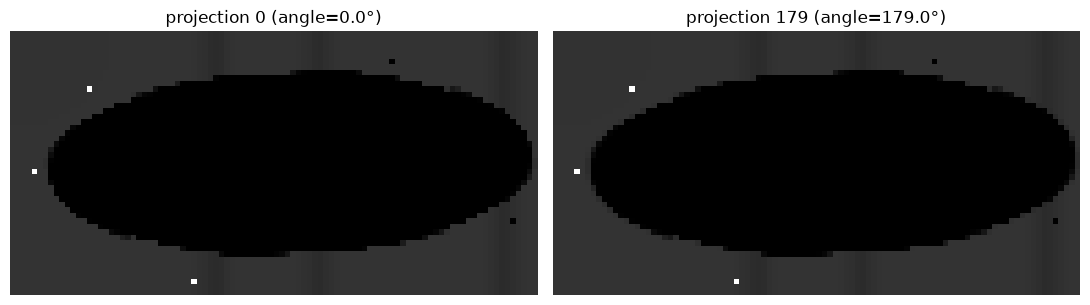

In [4]:
import matplotlib.pyplot as plt

n_angles = phantom.projections.shape[0]
first = di.get_projections(index=0)
last = di.get_projections(index=n_angles - 1)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].imshow(first, cmap="gray")
axes[0].set_title(f"projection 0 (angle={phantom.angles[0]:.1f}°)")
axes[1].imshow(last, cmap="gray")
axes[1].set_title(f"projection {n_angles - 1} (angle={phantom.angles[-1]:.1f}°)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Flat and dark fields

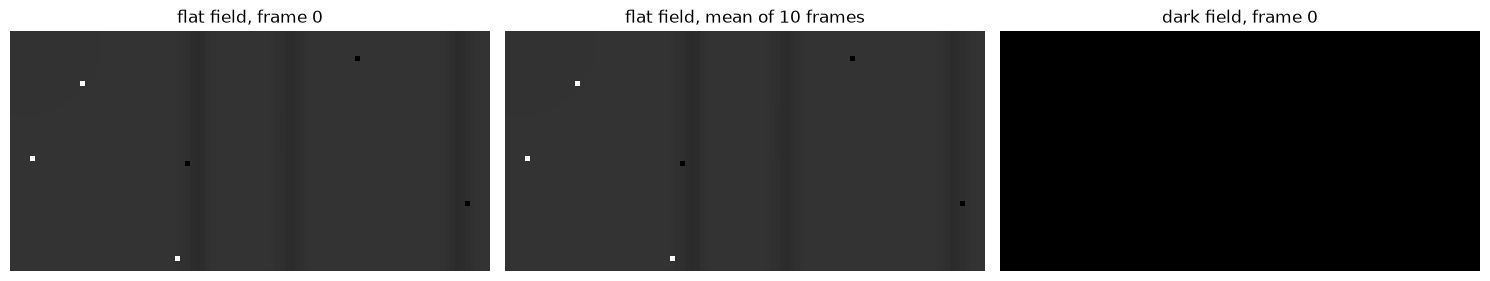

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(phantom.flat_field[0], cmap="gray")
axes[0].set_title("flat field, frame 0")
axes[1].imshow(phantom.flat_field.mean(axis=0), cmap="gray")
axes[1].set_title(f"flat field, mean of {phantom.flat_field.shape[0]} frames")
axes[2].imshow(phantom.dark_field[0], cmap="gray")
axes[2].set_title("dark field, frame 0")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

The scratches show up as thin vertical bands (fixed detector columns, present in every flat frame), the defective pixels as isolated bright/dark specks, and the smooth low-frequency shading is the simulated detector non-uniformity -- averaging frames (middle panel) reduces the per-frame noise but the fixed-pattern defects stay exactly where they are, which is precisely why they survive flat-field correction and turn into ring artifacts later.

## 5. Confirming the injected tilt and center-of-rotation deviation

Comparing against a second phantom generated with the exact same volume, angles, and detector -- but `cor_deviation=0, tilt_deg=0` -- isolates the geometric effect from everything else (detector defects, noise). Working with the ideal (pre-detector) line integrals here, not the raw detector counts, so this is purely about geometry.

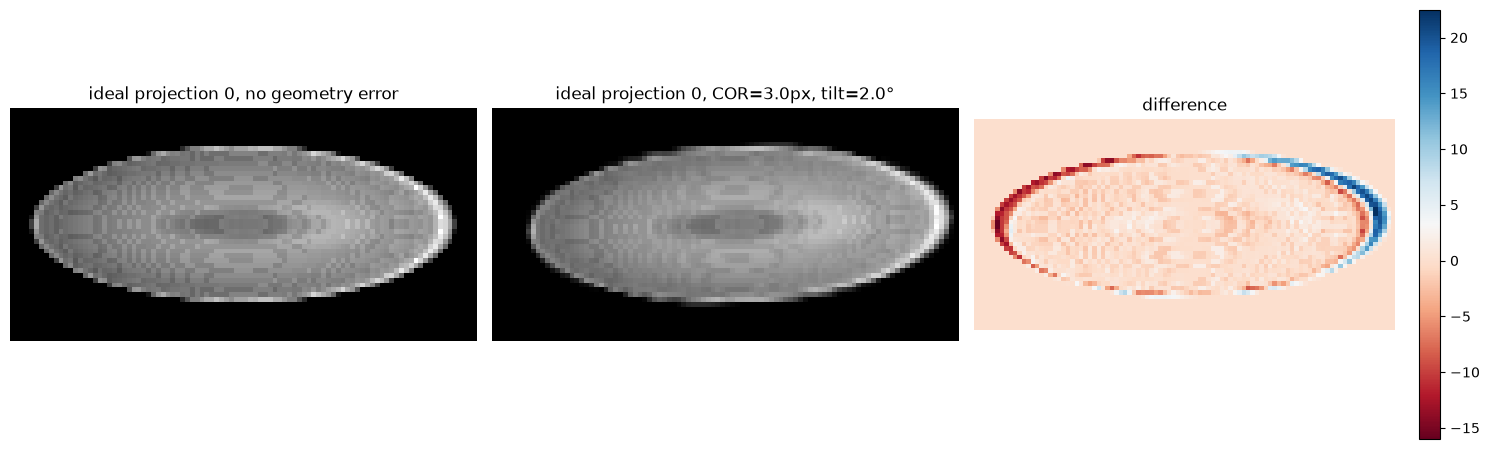

In [6]:
from tests.fixtures.realistic_phantom.simulate import apply_cor_and_tilt, project_parallel

ideal_with_geometry_error = apply_cor_and_tilt(
    project_parallel(phantom.volume, phantom.angles), TRUE_COR, TRUE_TILT
)
ideal_reference = project_parallel(phantom.volume, phantom.angles)  # cor=0, tilt=0

diff = ideal_with_geometry_error[0] - ideal_reference[0]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(ideal_reference[0], cmap="gray")
axes[0].set_title("ideal projection 0, no geometry error")
axes[1].imshow(ideal_with_geometry_error[0], cmap="gray")
axes[1].set_title(f"ideal projection 0, COR={TRUE_COR}px, tilt={TRUE_TILT}°")
im = axes[2].imshow(diff, cmap="RdBu")
axes[2].set_title("difference")
for ax in axes:
    ax.axis("off")
plt.colorbar(im, ax=axes[2], fraction=0.046)
plt.tight_layout()
plt.show()

The difference panel shows exactly the two injected effects at once: a roughly uniform sideways offset from the center-of-rotation shift, plus a diagonal edge pattern from the tilt (rotating the image tilts edges by different amounts depending on height, which is why the tilt component of the difference grows away from the image's vertical center).

Isolating the center-of-rotation deviation specifically: in an ideal 0°/180° pair, `flip(projection(180°))` should land exactly on `projection(0°)` if the rotation axis is centered. A deviation shows up as a horizontal shift between the two, roughly `2 × cor_deviation` pixels:

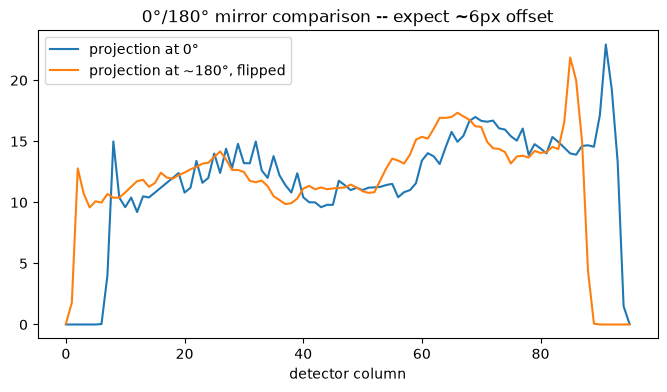

In [7]:
row = ideal_with_geometry_error.shape[1] // 2  # a central height row

profile_0 = ideal_with_geometry_error[0, row, :]
profile_180_flipped = ideal_with_geometry_error[-1, row, ::-1]

plt.figure(figsize=(8, 4))
plt.plot(profile_0, label="projection at 0°")
plt.plot(profile_180_flipped, label="projection at ~180°, flipped")
plt.legend()
plt.title(f"0°/180° mirror comparison -- expect ~{2 * TRUE_COR:.0f}px offset")
plt.xlabel("detector column")
plt.show()

## 6. Normalizing -- raw vs. normalized

Flat/dark correction, applied to every projection at once.

In [8]:
import numpy as np
from preprocessing import build_reference, normalize_rows

reference = build_reference(project)
normalized = normalize_rows(project, slice(None), reference)

n_bad = (~np.isfinite(normalized)).sum()
print("raw projections range:   ", phantom.projections.min(), "-", phantom.projections.max())
print("normalized range (finite values only):", np.nanmin(normalized[np.isfinite(normalized)]),
      "-", np.nanmax(normalized[np.isfinite(normalized)]))
print(f"non-finite pixels in normalized result: {n_bad} (out of {normalized.size})")

raw projections range:    0.02 - 5.02
normalized range (finite values only): 1.8587427e-09 - 1.0000001
non-finite pixels in normalized result: 540 (out of 829440)


D:\GitHub\Universial-Reconstructions - Copy\.claude\worktrees\code-package-review-13feda\preprocessing\normalization.py:100: RuntimeWarning: divide by zero encountered in divide
  return (raw - reference.dark) / (reference.flat - reference.dark)


Those non-finite pixels are real, not a bug: some of the injected defective pixels are *dead* (gain forced to 0), so at that exact detector position `flat - dark` is exactly zero and the correction divides by it. A truly dead pixel does exactly this in a real detector too -- naive flat/dark correction alone can't fix it, which is precisely why ring/defect-removal exists as its own step, not something `normalize()` is meant to solve. Clipping the display range below so those few pixels don't wash out the whole image, rather than hiding that they're there.

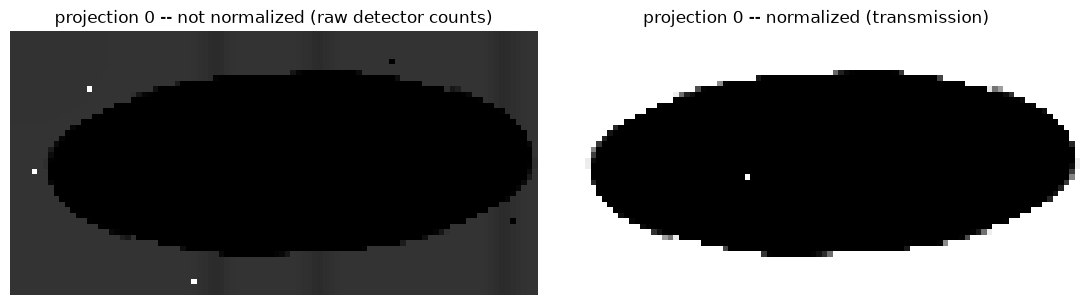

In [9]:
finite = normalized[np.isfinite(normalized)]
vmin, vmax = np.percentile(finite, [1, 99])

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].imshow(phantom.projections[0], cmap="gray")
axes[0].set_title("projection 0 -- not normalized (raw detector counts)")
axes[1].imshow(normalized[0], cmap="gray", vmin=vmin, vmax=vmax)
axes[1].set_title("projection 0 -- normalized (transmission)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

The raw panel is dominated by the detector's own brightness pattern (the flat-field shading, scratches, and defective pixels all still visible); the normalized panel is expressed as transmission through the object instead -- close to 1.0 where nothing attenuates the beam, dropping toward 0 through denser parts of the phantom, with the fixed-pattern detector defects largely (not perfectly -- see the note above, and the ring-removal step for the rest) divided out.

## Recap

```
generate() -> PhantomProject -> to_project_object() -> ProjectObject
                                        |
                                        +-- build_reference() + normalize_rows() -> normalized sinograms
```

Ground truth (`TRUE_COR`, `TRUE_TILT`) is exactly what a real calibration stage would need to *discover* -- this notebook only gets to see it because it's the one that injected it in the first place. See [`doc/REALISTIC_PHANTOM.md`](../REALISTIC_PHANTOM.md) for the full parameter reference and the forward model this generator uses.